## Подробное исследование признаков

В данном ноутбуке представлена история исследования данных и введение правил обработки.

Загрузка необходимых библиотек и исходных данных

In [19]:
import sys
import os
sys.path.append(os.path.abspath('..'))

In [20]:
import pandas as pd
import numpy as np
import seaborn as sns
from src.utils import evaluate_preds, show_metrics
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from catboost import CatBoostClassifier, CatBoostRegressor

df = pd.read_csv('../data/raw/train.csv')

Начнем обработку категориальных признаков. Рассмотрим `Home Ownership`. Он может принимать значение `Have Mortgage`, оно равнозначно по смыслу со значением `Home Mortgage`. Сформулируем правило исправления:
1. `Home Ownerhip = Home Mortgage` при `Home Ownership = Have Mortgage`

In [21]:
home_ownership_is_have_morgage_mask = (df['Home Ownership'] == 'Have Mortgage')
df.loc[home_ownership_is_have_morgage_mask, 'Home Ownership'] = 'Home Mortgage'

Рассмотрим категориальный признак `Years in current job`. Он принимает строковые значения: `< 1 year`, `1 year` ... `10 years`, `10+ years` и имеет пропущенные значения. Опишем порядок преобразования строковых значений в численное:
1. Значения `< 1 year` и `10+ years` изменяем на `1 year` и `10 years` соответственно. Оставляем флаги `less_1_year_in_current_job` и `more_10_years_in_current_job`
2. Применяем функцию `split` и преобразуем первый элемент к целочисленному значению

К выбору метода для заполнения пропусков вернемся после очистки выбросов остальных признаков

In [22]:
yicj_less_1_year_mask = (df['Years in current job'] == '< 1 year')
yicj_more_10_years_mask = (df['Years in current job'] == '10+ years')

df['less_1_year_in_current_job'] = yicj_less_1_year_mask * 1
df['more_10_years_in_current_job'] = yicj_more_10_years_mask * 1

df.loc[yicj_less_1_year_mask, 'Years in current job'] = '1 year'
df.loc[yicj_more_10_years_mask, 'Years in current job'] = '10 years'

df['Years in current job'] = df['Years in current job'].apply(lambda g: int(g.split(' ')[0]) if isinstance(g, str) else g)

Оставшиеся категориальные признаки не имеют пропусков и не требуют коррекций. Заменим все категории дамми-переменными

In [23]:
df = pd.get_dummies(data=df, prefix=None, prefix_sep='_', columns=['Home Ownership', 'Purpose', 'Term'], drop_first=True, dtype=int)
df.head()

,Annual Income,Years in current job,Tax Liens,Number of Open Accounts,Years of Credit History,Maximum Open Credit,Number of Credit Problems,Months since last delinquent,Bankruptcies,Current Loan Amount,...,Purpose_major purchase,Purpose_medical bills,Purpose_moving,Purpose_other,Purpose_renewable energy,Purpose_small business,Purpose_take a trip,Purpose_vacation,Purpose_wedding,Term_Short Term
0,482087.0,NaN,0.0,11.0,26.3,685960.0,1.0,NaN,1.0,99999999.0,...,0,0,0,0,0,0,0,0,0,1
1,1025487.0,10.0,0.0,15.0,15.3,1181730.0,0.0,NaN,0.0,264968.0,...,0,0,0,0,0,0,0,0,0,0
2,751412.0,8.0,0.0,11.0,35.0,1182434.0,0.0,NaN,0.0,99999999.0,...,0,0,0,0,0,0,0,0,0,1
3,805068.0,6.0,0.0,8.0,22.5,147400.0,1.0,NaN,1.0,121396.0,...,0,0,0,0,0,0,0,0,0,1
4,776264.0,8.0,0.0,13.0,13.6,385836.0,1.0,NaN,0.0,125840.0,...,0,0,0,0,0,0,0,0,0,1


Рассмотрим признак `Annual Income`. Рассмотрим экстремальные значения `Annual Income > Q_99` (где Q_99 квартиль соответствующего признака)

,Annual Income,Years in current job,Tax Liens,Number of Open Accounts,Years of Credit History,Maximum Open Credit,Number of Credit Problems,Months since last delinquent,Bankruptcies,Current Loan Amount,...,Purpose_major purchase,Purpose_medical bills,Purpose_moving,Purpose_other,Purpose_renewable energy,Purpose_small business,Purpose_take a trip,Purpose_vacation,Purpose_wedding,Term_Short Term
166,4580976.0,4.0,0.0,18.0,25.5,1553530.0,0.0,NaN,0.0,99999999.0,...,0,0,0,0,0,0,0,0,0,0
422,4667616.0,3.0,0.0,4.0,5.9,472428.0,0.0,NaN,0.0,112596.0,...,0,0,0,0,0,0,1,0,0,1
585,4772800.0,8.0,0.0,9.0,35.5,0.0,0.0,NaN,0.0,99999999.0,...,0,0,0,0,0,1,0,0,0,1
602,5631030.0,1.0,0.0,5.0,17.5,0.0,0.0,NaN,0.0,99999999.0,...,0,0,0,0,0,0,0,0,0,1
693,5605950.0,1.0,0.0,12.0,23.1,976074.0,0.0,9.0,0.0,757306.0,...,0,0,0,0,0,0,0,0,0,1
837,5131482.0,2.0,0.0,16.0,20.7,4860504.0,0.0,16.0,0.0,756228.0,...,0,0,0,0,0,0,0,0,0,1
924,4757885.0,1.0,0.0,3.0,33.5,764654.0,0.0,68.0,0.0,161898.0,...,0,0,0,0,0,0,0,0,0,1
1025,8923844.0,3.0,0.0,15.0,17.2,1452000.0,0.0,NaN,0.0,670428.0,...,0,0,0,0,0,0,0,0,0,1
1078,4846425.0,10.0,2.0,11.0,20.1,716364.0,2.0,16.0,0.0,561176.0,...,0,0,0,0,0,0,0,0,0,1
1163,4523064.0,3.0,0.0,6.0,14.2,0.0,0.0,38.0,0.0,392788.0,...,0,0,0,0,0,0,0,0,0,0


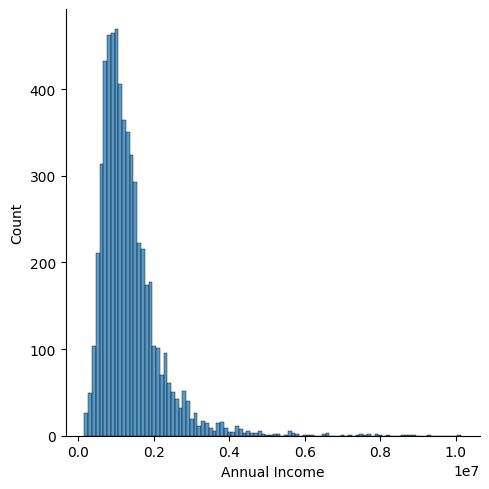

In [24]:
annual_income_q99 = df['Annual Income'].quantile(0.99)
annual_income_gt_q99_mask = (df['Annual Income'] >= annual_income_q99)
display(df[annual_income_gt_q99_mask])
sns.displot(df['Annual Income'], bins=100)

Не будем корректировать высокие значения, так как распределение выглядит вполне естественно (нормальное с правым хвостом) для признака финансовой природы.

Сформулируем идею для добавления новых признаков: добавить признак `log_income = log(Annual income)`

Рассмотрим признак `Number of Open Accounts`. Правило обработки:
1. Значения `Number of open accounts > Q_99` будем считать выбросами и заменять медианой. Оставим флаг `number_of_open_accounts_was_scaled`

In [25]:
noa_q99 = df['Number of Open Accounts'].quantile(0.99)
noa_greater_q99 = (df['Number of Open Accounts'] > noa_q99)
df['number_of_open_accounts_was_scaled'] = noa_greater_q99
df.loc[noa_greater_q99, 'Number of Open Accounts'] = df['Number of Open Accounts'].median()

Рассмотрим признак `Maximum Open Credit`. Правило обработки:
1. `Maximum Open Credit = median` для `Maximum Open Credit > 0.15e9`
2. `Maximum Open Credit = median` для `Maximum Open Credit = 0`

In [26]:
moc_big_value_mask = (df['Maximum Open Credit'] > 1e7) & (df['Maximum Open Credit'].notna())
df.loc[moc_big_value_mask, 'Maximum Open Credit'] = df['Maximum Open Credit'].median()
moc_0_mask = (df['Maximum Open Credit'] == 0)
df.loc[moc_0_mask, 'Maximum Open Credit'] = df['Maximum Open Credit'].median()

Рассмотрим признак `Current Loan Amount`. У всех объектов, у которых `Current Loan Amount = 99999999` значение `Credit Default = 0`. Оставим флаг для этих значений и заменим медианой.

In [27]:
cla_scaled_mask = df['Current Loan Amount'] == 99999999.0
display(df.loc[cla_scaled_mask, 'Credit Default'].value_counts())

df['current_loan_amount_scaled'] = cla_scaled_mask * 1
df.loc[cla_scaled_mask, 'Current Loan Amount'] = df['Current Loan Amount'].median()

Credit Default
0    870
Name: count, dtype: int64

Рассмотрим признак `Monthly Dept`. Правило для коррекции:
1. `Monthly Dept = Current Loan Amount` при `Monthly Dept > Current Loan Amount` (Для погашения займа осталась одна выплата)
2. `Montly Dept = Current Loan Amount` при `Montly Dept = 0`

In [ ]:
monthly_debt_gt_cla_mask = (df['Monthly Debt'] > df['Current Loan Amount']) | (df['Monthly Debt'] == 0)
df.loc[monthly_debt_gt_cla_mask, 'Monthly Debt'] = df.loc[monthly_debt_gt_cla_mask, 'Current Loan Amount']

Рассмотрим признак `Credit Score`. Заметим, что большинство объектов имеют `Credit Score` в диапозоне от 585 до 751, а все значения, первышающие 751 оканчиваются на 0. Можно сделать вывод, что большие значения (> 751) носят не случайный характер. Все объекты `Credit Score` которых превышает 751 имеют `Credit Default` 1. Правила для исправления:
1. Оставляем флаг `credit_score_scaled`
2. `Credit Score = Credit Score // 10` для объектов у которых `Credit Score > 751`.  

In [12]:
print(np.sort(df.loc[df['Credit Score'] < 1000, 'Credit Score'].dropna().unique()))
print(np.sort(df.loc[df['Credit Score'] > 1000, 'Credit Score'].dropna().unique()))
display(df.loc[df['Credit Score'] > 751, 'Credit Default'].value_counts())

credit_score_scaled_mask = (df['Credit Score'] > 751)
df['credit_score_scaled'] = credit_score_scaled_mask
df.loc[credit_score_scaled_mask, 'Credit Score'] = df.loc[credit_score_scaled_mask, 'Credit Score'] // 10

[585. 586. 588. 589. 590. 591. 593. 594. 597. 598. 599. 601. 602. 604.
 606. 607. 608. 609. 610. 611. 612. 613. 614. 615. 616. 617. 618. 619.
 620. 621. 622. 624. 625. 626. 627. 628. 629. 630. 631. 632. 633. 634.
 635. 636. 637. 638. 639. 640. 642. 643. 644. 645. 646. 647. 648. 649.
 650. 651. 652. 653. 654. 655. 656. 657. 658. 659. 660. 661. 662. 663.
 664. 665. 666. 667. 668. 669. 670. 671. 672. 673. 674. 675. 676. 677.
 678. 679. 680. 681. 682. 683. 684. 685. 686. 687. 688. 689. 690. 691.
 692. 693. 694. 695. 696. 697. 698. 699. 700. 701. 702. 703. 704. 705.
 706. 707. 708. 709. 710. 711. 712. 713. 714. 715. 716. 717. 718. 719.
 720. 721. 722. 723. 724. 725. 726. 727. 728. 729. 730. 731. 732. 733.
 734. 735. 736. 737. 738. 739. 740. 741. 742. 743. 744. 745. 746. 747.
 748. 749. 750. 751.]
[6060. 6110. 6150. 6160. 6170. 6180. 6210. 6220. 6230. 6270. 6280. 6320.
 6410. 6450. 6470. 6480. 6490. 6500. 6520. 6560. 6570. 6580. 6590. 6600.
 6610. 6620. 6630. 6640. 6650. 6670. 6680. 6690. 67

Credit Default
1    400
Name: count, dtype: int64

## Исследование пропусков в данных

Рассмотри пропуски в признаке `Months since last delinquent`. Используемое правило заполнения:
1. `Months since last delinquent = 0` для объектов у которых `Number of Credit Problems > 0` (неуплата в текущем месяце)
2. `Months since last delinqunt = -1` + `not_debtor` для объектов, у которых `Number of Credit Problems = 0` (не было пропущенных платежей)

In [13]:
msld_isna_nocp_1 = df['Months since last delinquent'].isna() & (df['Number of Credit Problems'] >= 1)
msld_isna_nocp_0 = df['Months since last delinquent'].isna() & (df['Number of Credit Problems'] == 0)
df['not_debtor'] = msld_isna_nocp_0
df.loc[msld_isna_nocp_1, 'Months since last delinquent'] = 0
df.loc[msld_isna_nocp_0, 'Months since last delinquent'] = -1

In [14]:
def yicj_median_imputer(df):
    X = df.copy()
    train_mask = X['Years in current job'].notna()
    X = X[train_mask]
    y = X['Years in current job']
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.25)
    median_imputer = np.ones_like(y_test) * y_train.median() 
    show_metrics(y_test, median_imputer, average='macro')

def yicj_knn_imputer(df):
    X = df.copy()
    train_mask = X['Years in current job'].notna()
    X = X[train_mask].dropna()
    y = X['Years in current job']
    X.drop(columns=['Years in current job', 'Credit Default'], inplace=True)
    scaler = RobustScaler()
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    knn_imputer = KNeighborsClassifier(n_neighbors=6)
    knn_imputer.fit(X_train, y_train)
    y_pred = knn_imputer.predict(X_test)
    y_pred_proba = knn_imputer.predict_proba(X_test)[:, 1]
    show_metrics(y_test, y_pred, y_pred_proba, average='weighted')

def yicj_catboost_imputer(df):
    X = df.copy()
    train_mask = X['Years in current job'].notna()
    X = X[train_mask].dropna()
    y = X['Years in current job']
    X.drop(columns=['Years in current job', 'Credit Default'], inplace=True)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
    frozen_params = {
        'silent':True,
        #'cat_features':CAT_FEATURE_NAMES,
        'eval_metric':'MultiClass',
        'early_stopping_rounds':20,
        'random_state':42
    }
    catboost_imputer = CatBoostClassifier(**frozen_params)
    catboost_imputer.fit(X_train, y_train)
    y_pred = catboost_imputer.predict(X_test)
    y_pred_proba = catboost_imputer.predict_proba(X_test)[:, 1]
    show_metrics(y_test, y_pred, y_pred_proba, average='weighted')
    return catboost_imputer


yicj_median_imputer(df)
print('#'*20)
yicj_knn_imputer(df)
print('#'*20)
catboost_imputer_yicj = yicj_catboost_imputer(df)

Точность (accuracy)  = 0.05776780706674145
Точность (precision) = 0.005776780706674145
Полнота (recall)     = 0.1
f1_score             = 0.010922587486744432
####################
Точность (accuracy)  = 0.45138396025550037
Точность (precision) = 0.40653077404856724
Полнота (recall)     = 0.45138396025550037
f1_score             = 0.4264707751765905
####################
Точность (accuracy)  = 0.5031937544357701
Точность (precision) = 0.5092327488358003
Полнота (recall)     = 0.5031937544357701
f1_score             = 0.5039448580195763


Даже без подобранных гиперпараметров, catboost справляется c заполнением лучше остальных предложенных методов. Будем использовать его как основной. Подбор гиперпараметров реализуем в transformers.py

In [15]:
yicj_isna_mask = df['Years in current job'].isna()
temp = df[yicj_isna_mask].drop(columns=['Years in current job', 'Credit Default'])
df.loc[yicj_isna_mask, 'Years in current job'] = catboost_imputer_yicj.predict(temp)

Аналогичный тест проведем и для признака `Bankruptcies`

In [16]:
def bankrupties_median_imputer(df):
    X = df.copy()
    train_mask = X['Bankruptcies'].notna()
    X = X[train_mask]
    y = X['Bankruptcies']
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.25)
    median_imputer = np.ones_like(y_test) * y_train.median() 
    show_metrics(y_test, median_imputer, average='macro')

def bankrupties_knn_imputer(df):
    X = df.copy()
    train_mask = X['Bankruptcies'].notna()
    X = X[train_mask].dropna()
    y = X['Bankruptcies']
    X.drop(columns=['Bankruptcies', 'Credit Default'], inplace=True)
    scaler = RobustScaler()
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    knn_imputer = KNeighborsClassifier(n_neighbors=6)
    knn_imputer.fit(X_train, y_train)
    y_pred = knn_imputer.predict(X_test)
    y_pred_proba = knn_imputer.predict_proba(X_test)[:, 1]
    show_metrics(y_test, y_pred, y_pred_proba, average='weighted')

def bankrupties_catboost_imputer(df):
    X = df.copy()
    train_mask = X['Bankruptcies'].notna()
    X = X[train_mask].dropna()
    y = X['Bankruptcies']
    X.drop(columns=['Bankruptcies', 'Credit Default'], inplace=True)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
    frozen_params = {
        'silent':True,
        #'cat_features':CAT_FEATURE_NAMES,
        'eval_metric':'MultiClass',
        'early_stopping_rounds':20,
        'random_state':42
    }
    catboost_imputer = CatBoostClassifier(**frozen_params)
    catboost_imputer.fit(X_train, y_train)
    y_pred = catboost_imputer.predict(X_test)
    y_pred_proba = catboost_imputer.predict_proba(X_test)[:, 1]
    show_metrics(y_test, y_pred, y_pred_proba, average='weighted')
    return catboost_imputer


bankrupties_median_imputer(df)
print('#'*20)
bankrupties_knn_imputer(df)
print('#'*20)
bankrupties_catboost_imputer(df)

Точность (accuracy)  = 0.8931623931623932
Точность (precision) = 0.2232905982905983
Полнота (recall)     = 0.25
f1_score             = 0.23589164785553046
####################
Точность (accuracy)  = 0.9298718813216453
Точность (precision) = 0.9168596292573696
Полнота (recall)     = 0.9298718813216453
f1_score             = 0.9203871965648288
####################
Точность (accuracy)  = 0.9777478084962913
Точность (precision) = 0.9794584545596009
Полнота (recall)     = 0.9777478084962913
f1_score             = 0.9776774698927008


CatBoostClassifier(early_stopping_rounds=20, eval_metric='MultiClass', random_state=42, silent=True)

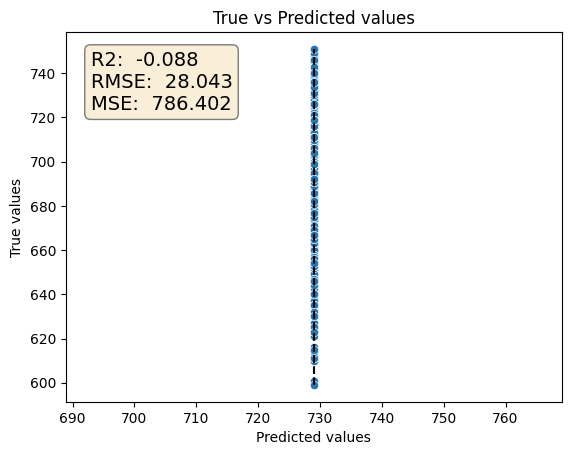

####################


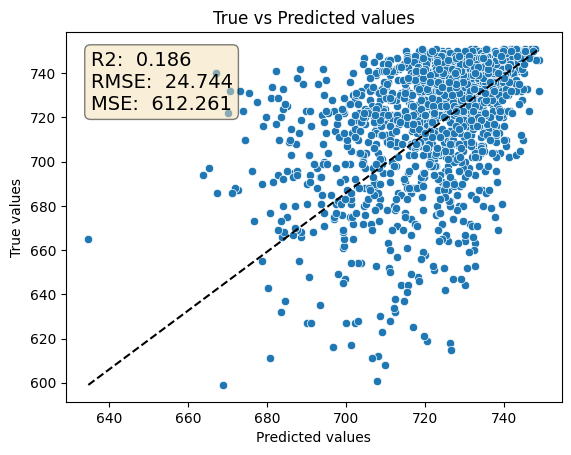

####################


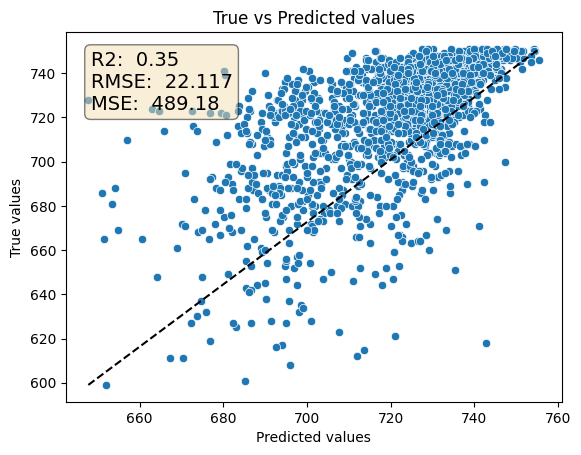

CatBoostRegressor(early_stopping_rounds=20, eval_metric='RMSE', loss_function='RMSE', random_state=42, silent=True)

In [17]:
def credit_score_median_imputer(df):
    X = df.copy()
    train_mask = X['Credit Score'].notna()
    X = X[train_mask]
    y = X['Credit Score']
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.25)
    median_imputer = np.ones_like(y_test) * y_train.median() 
    evaluate_preds(y_test, median_imputer)

def credit_score_knn_imputer(df):
    X = df.copy()
    train_mask = X['Credit Score'].notna()
    X = X[train_mask].dropna()
    y = X['Credit Score']
    X.drop(columns=['Credit Score', 'Credit Default'], inplace=True)
    scaler = RobustScaler()
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    knn_imputer = KNeighborsRegressor(n_neighbors=6)
    knn_imputer.fit(X_train, y_train)
    y_pred = knn_imputer.predict(X_test)
    evaluate_preds(y_test, y_pred)

def credit_score_catboost_imputer(df):
    X = df.copy()
    train_mask = X['Credit Score'].notna()
    X = X[train_mask].dropna()
    y = X['Credit Score']
    X.drop(columns=['Credit Score', 'Credit Default'], inplace=True)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
    frozen_params = {
        'silent':True,
        #'cat_features':CAT_FEATURE_NAMES,
        'eval_metric':'RMSE',
        'early_stopping_rounds':20,
        'random_state':42
    }
    catboost_imputer = CatBoostRegressor(**frozen_params)
    catboost_imputer.fit(X_train, y_train)
    y_pred = catboost_imputer.predict(X_test)
    evaluate_preds(y_test, y_pred)
    return catboost_imputer


credit_score_median_imputer(df)
print('#'*20)
credit_score_knn_imputer(df)
print('#'*20)
credit_score_catboost_imputer(df)

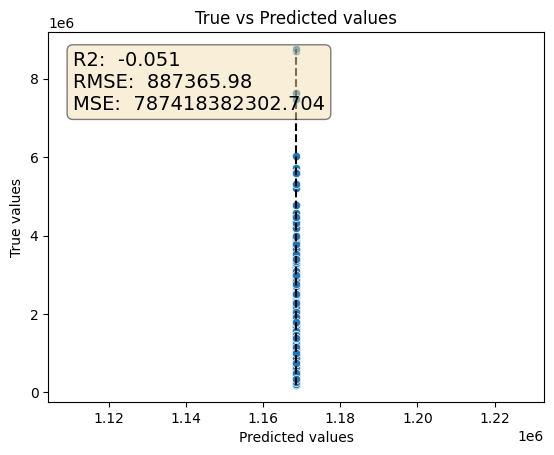

####################


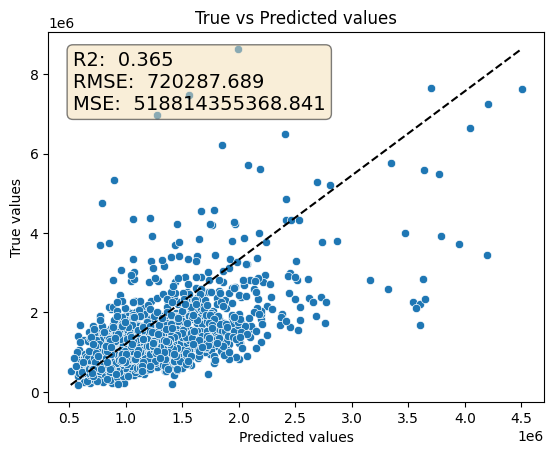

####################


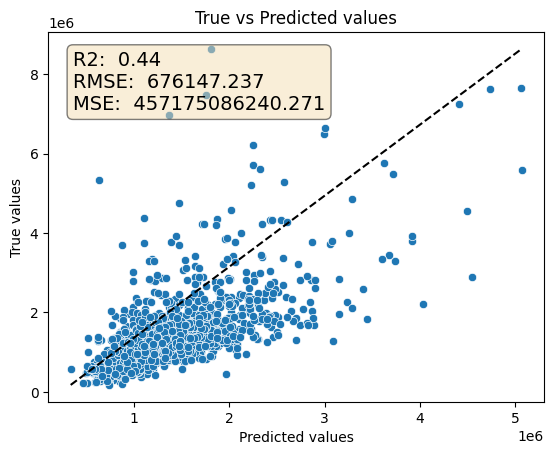

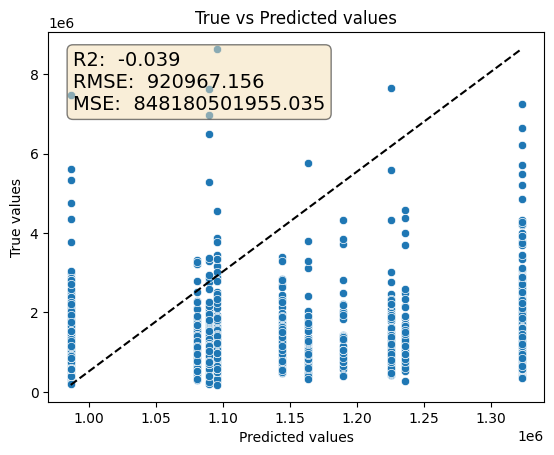

In [18]:
def annual_income_median_imputer(df):
    X = df.copy()
    train_mask = X['Annual Income'].notna()
    X = X[train_mask]
    y = X['Annual Income']
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.25)
    median_imputer = np.ones_like(y_test) * y_train.median() 
    evaluate_preds(y_test, median_imputer)

def annual_income_knn_imputer(df):
    X = df.copy()
    train_mask = X['Annual Income'].notna()
    X = X[train_mask].dropna()
    y = X['Annual Income']
    X.drop(columns=['Annual Income', 'Credit Default'], inplace=True)
    scaler = RobustScaler()
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    knn_imputer = KNeighborsRegressor(n_neighbors=6)
    knn_imputer.fit(X_train, y_train)
    y_pred = knn_imputer.predict(X_test)
    evaluate_preds(y_test, y_pred)

def annual_income_catboost_imputer(df):
    X = df.copy()
    train_mask = X['Annual Income'].notna()
    X = X[train_mask].dropna()
    y = X['Annual Income']
    X.drop(columns=['Annual Income', 'Credit Default'], inplace=True)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
    frozen_params = {
        'silent':True,
        #'cat_features':CAT_FEATURE_NAMES,
        'eval_metric':'RMSE',
        'early_stopping_rounds':20,
        'random_state':42
    }
    catboost_imputer = CatBoostRegressor(**frozen_params)
    catboost_imputer.fit(X_train, y_train)
    y_pred = catboost_imputer.predict(X_test)
    evaluate_preds(y_test, y_pred)
    return catboost_imputer

def median_by_job(df):
    X = df.copy()
    train_mask = X['Annual Income'].notna()
    X = X[train_mask].dropna()
    y = X['Annual Income']
    X.drop(columns=['Credit Default'], inplace=True)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
    temp = pd.DataFrame()
    temp = X_train[['Years in current job', 'Annual Income']]
    median_by_job = temp.groupby('Years in current job')['Annual Income'].median()
    y_pred = X_test['Years in current job'].map(median_by_job)
    evaluate_preds(y_test, y_pred)



annual_income_median_imputer(df)
print('#'*20)
annual_income_knn_imputer(df)
print('#'*20)
annual_income_catboost_imputer(df)
median_by_job(df)

Порядок преобразований:
1. `Home Ownerhip = Home Mortgage` для `Home Ownership = Have Mortgage`
2. Значения `< 1 year` и `10+ years` изменяем на `1 year` и `10 years` соответственно. Оставляем флаги `less_1_year_in_current_job` и `more_10_years_in_current_job`
3. Значения `Number of open accounts > Q_99` будем считать выбросами и заменять медианой. Оставим флаг `number_of_open_accounts_was_scaled`
4.  `Maximum Open Credit = median` для `Maximum Open Credit > 1e7` и  `Maximum Open Credit = 0`
5. `Current Loan Amount = median` для `Current Loan Amount = 99999999` + флаг `current_loan_amount_scaled`
6. `Monthly Dept = Current Loan Amount` для `Monthly Dept > Current Loan Amount`
7. `Credit Score = Credit Score // 10` для `Credit Score > 751` + флаг `credit_score_scaled`
8. `Months since last delinquent = 0` для `Number of Credit Problems > 0` 
9. `Months since last delinqunt = -1` + флаг `not_debtor` для `Number of Credit Problems = 0`
10. Заполнение `Years in current job` при помощи `CatBoost` + флаг `years_in_current_job_filled`
11. Заполнение `Bankrupties` при помощи `CatBoost` + флаг `bankrupties_filled`
12. Заполнение `Credit Score` при помощи `CatBoost` + флаг `credit_score_filled`
13. Заполнение `Annual Income` при помощи `CatBoost` + флаг `annual_income_filled`